# VAE Transformer: De novo generation of molecules

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

Prof. Victor S. Batista

*An earlier version of this assignment was designed by Dr. Haote Li.*

**Version 1.0 · November 2026 · runs on Google Colab with a GPU runtime (T4 is enough).**
**How to cite:** V. S. Batista, *VAE Transformer: De novo generation of molecules*, CHEM 584 tutorial notebook, version 1.0 (2026).
**License:** text CC BY 4.0, code MIT.

## 1. Introduction

The number of drug-like molecules is astronomically large, far too large to enumerate or to screen exhaustively. **Generative models** propose new candidate structures by learning what molecules "look like" from a large collection of examples, and then sampling new ones. Because a molecule can be written as a line of text, a **SMILES string** such as `CC(=O)O` for acetic acid, we can borrow the machinery that was built for language: the **Transformer**.

**Goal.** Generate new molecules of the same type as those in a training set (250,000 drug-like molecules from the ZINC library), using a Transformer combined with a variational-autoencoder-type latent space.

### What you will learn
After working through this notebook you will be able to:
1. turn SMILES strings into the padded token matrices that a Transformer needs, and explain each preprocessing choice;
2. describe how the encoder, the latent bottleneck and the decoder of the model fit together (Figure 1);
3. explain what the **MMD penalty** does, and why a plain autoencoder cannot generate molecules from random numbers;
4. evaluate a molecular generator honestly: **validity, uniqueness, novelty and reconstruction accuracy**, with error bars and a look at *how* it fails;
5. use the latent space: check that it matches its prior, colour it by molecular properties, and **interpolate between two molecules**.

### What you need
Basic Python and PyTorch, and some familiarity with neural networks. The Transformer ingredients needed here are summarised in Section 4, with pointers to the original papers (see References at the end).

### Roadmap

| Section | Content | Time on a T4 |
|---|---|---|
| 1 | Introduction | |
| 2 | Setup: libraries, device, seeds | |
| 3 | Data: ZINC, tokenisation, padding, batches | |
| 4 | The model: Transformer and MMD autoencoder | |
| 5 | Training (optional) and loading the pre-trained model | training: about 5 min per epoch (skipped by default) |
| 6 | Evaluation: reconstruction, latent space, sampling | canonicalising ZINC takes about 1.5 minutes |
| 7 | Interpolating between two molecules | |
| 8 | Check your understanding and exercises | |

**How to run.** Select a GPU runtime (**Runtime → Change runtime type → GPU**), then run the cells from top to bottom. The ZINC data are downloaded automatically. The pre-trained model file has to be provided by you (Section 3.1). Cells whose code is hidden (form cells) are just plumbing; click *Show code* if you are curious.

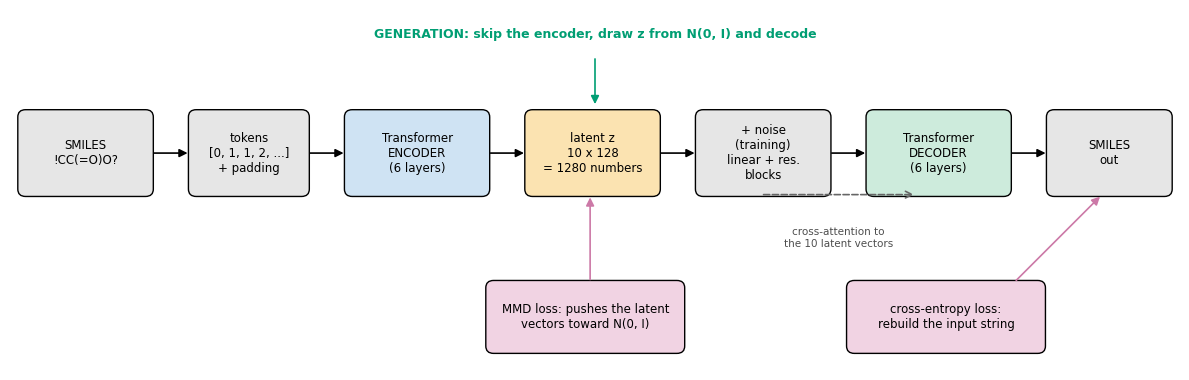

In [1]:
#@title Figure 1: the model at a glance { display-mode: "form" }
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="k", lw=1))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=8.5)

def arrow(ax, p, q, color="k", style="-|>", ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=12, lw=1.2, color=color, linestyle=ls))

fig, ax = plt.subplots(figsize=(12, 3.9))
ax.set_xlim(0, 12); ax.set_ylim(0, 3.9); ax.axis("off")
blue, green, orange, pink, gray = "#cfe3f3", "#cdebdc", "#fbe3b1", "#f1d3e3", "#e6e6e6"

box(ax, 0.1, 1.9, 1.35, 0.9, "SMILES\n!CC(=O)O?", gray)
box(ax, 1.85, 1.9, 1.2, 0.9, "tokens\n[0, 1, 1, 2, ...]\n+ padding", gray)
box(ax, 3.45, 1.9, 1.45, 0.9, "Transformer\nENCODER\n(6 layers)", blue)
box(ax, 5.3, 1.9, 1.35, 0.9, "latent z\n10 x 128\n= 1280 numbers", orange)
box(ax, 7.05, 1.9, 1.35, 0.9, "+ noise\n(training)\nlinear + res.\nblocks", gray)
box(ax, 8.8, 1.9, 1.45, 0.9, "Transformer\nDECODER\n(6 layers)", green)
box(ax, 10.65, 1.9, 1.25, 0.9, "SMILES\nout", gray)
for x0, x1 in [(1.45, 1.85), (3.05, 3.45), (4.9, 5.3), (6.65, 7.05), (8.4, 8.8), (10.25, 10.65)]:
    arrow(ax, (x0, 2.35), (x1, 2.35))
# decoder attends to the latent memory
arrow(ax, (7.7, 1.9), (9.3, 1.9), color="0.4", style="->", ls="--")
ax.text(8.5, 1.55, "cross-attention to\nthe 10 latent vectors", ha="center", va="top", fontsize=7.5, color="0.3")
# losses
box(ax, 4.9, 0.2, 2.0, 0.75, "MMD loss: pushes the latent\nvectors toward N(0, I)", pink)
arrow(ax, (5.95, 0.95), (5.95, 1.9), color="#CC79A7")
box(ax, 8.6, 0.2, 2.0, 0.75, "cross-entropy loss:\nrebuild the input string", pink)
arrow(ax, (10.3, 0.95), (11.2, 1.9), color="#CC79A7")
# generation path
ax.text(6.0, 3.6, "GENERATION: skip the encoder, draw z from N(0, I) and decode", ha="center", fontsize=9, color="#009E73", weight="bold")
arrow(ax, (6.0, 3.4), (6.0, 2.85), color="#009E73")
plt.tight_layout(); plt.show()

**Figure 1.** A SMILES string is converted to tokens and compressed by a Transformer encoder into a small **latent** representation (10 vectors of 128 numbers). A Transformer decoder rebuilds the string from it, attending to these 10 vectors. Training minimises the reconstruction error (cross-entropy) plus a penalty (MMD) that makes the latent vectors look like draws from a standard normal distribution. That second term is what allows us to **generate**: after training, random numbers from N(0, I) are valid inputs to the decoder.

## 2. Setup

### 2.1 Install libraries
Colab already provides PyTorch, NumPy, pandas, scikit-learn and Matplotlib. We only need to add two packages: **RDKit**, an open-source cheminformatics toolkit that we use to check whether a generated string describes a real molecule, to compute properties and to build 3D structures; and **py3Dmol**, which displays molecules as interactive 3D views.

In [2]:
#@title Install RDKit and py3Dmol { display-mode: "form" }
%pip install -q rdkit
%pip install -q py3Dmol

### 2.2 Imports, seeds and helper functions
The next cell imports everything we need, fixes the **random seeds** (so that sampling is reproducible), selects the **device** (GPU if available), prints the versions of the main packages, and defines two tests for generated SMILES strings:

* `is_SMILE(name)`: can RDKit *parse* the string? (a grammar check only, `sanitize=False`)
* `is_valid_molecule(name)`: does it also pass RDKit's *chemical sanitisation* (valence rules, aromaticity, ...)? This is the stricter and more meaningful test.

In [3]:
import os, sys, io, math, random, pickle, hashlib, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import rdkit
import py3Dmol
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import AllChem, Draw, QED, Crippen, rdFingerprintGenerator
from rdkit.Chem.Draw import IPythonConsole          # makes Mol objects render as pictures
RDLogger.DisableLog('rdApp.*')                      # RDKit prints many harmless error messages; silence them
try:
  IPythonConsole.drawOptions.bondLineWidth = 1.8
except AttributeError:
  pass

# --- reproducibility and a consistent figure style ------------------------------------------
SEED = 0
def set_seed(seed=SEED):
  random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")  # colour-blind safe
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

IN_COLAB = "google.colab" in sys.modules
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | RDKit {rdkit.__version__} | numpy {np.__version__} | pandas {pd.__version__}")
print(f"device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))
if device.type == 'cpu':
  print("WARNING: no GPU found. Use Runtime > Change runtime type > GPU; generation and training are very slow on CPU.")

def is_SMILE(name):
  # Input a SMILES string and return whether RDKit can PARSE it (grammar only, no chemistry checks)
  return(Chem.MolFromSmiles(name, sanitize=False) is not None)

def is_valid_molecule(name):
  # Stricter test: the string must parse AND pass RDKit's chemical sanitisation (valences, aromaticity, ...)
  return(len(name) > 0 and Chem.MolFromSmiles(name) is not None)

python 3.13.16 | torch 2.14.1+cu130 | RDKit 2026.09.2 | numpy 2.4.6 | pandas 2.2.3
device: cuda (Tesla T4)


### 2.3 Looking at molecules in 3D
Molecules are three-dimensional objects, so we display them with **py3Dmol**: interactive 3D views that you can **rotate (drag), zoom (scroll) and pan**. A SMILES string only describes which atoms are bonded to which, not where they sit in space, so the helper below first builds a plausible 3D structure with RDKit (hydrogens added, one conformer generated with the ETKDG method, then a quick force-field cleanup; hydrogens are hidden in the picture for clarity). Keep in mind that this is *one* plausible conformer, not a computed minimum-energy structure.

py3Dmol views are small JavaScript applications: they need a live Colab session and do not appear in static copies of the notebook (for example on GitHub or in a PDF). Set `MOL_VIEW = "2d"` in the cell below to get ordinary pictures instead.

In [4]:
#@title Helpers to view molecules { display-mode: "form" }
MOL_VIEW = "3d" #@param ["3d", "2d"]

def mol_to_3d(mol_or_smiles, seed=0):
  """RDKit molecule with 3D coordinates (hydrogens are hidden but the coordinates are kept); None if it fails."""
  mol = Chem.MolFromSmiles(mol_or_smiles) if isinstance(mol_or_smiles, str) else mol_or_smiles
  if mol is None:
    return None
  mh = Chem.AddHs(mol)                                    # hydrogens are needed for a sensible 3D geometry
  params = AllChem.ETKDGv3(); params.randomSeed = seed
  if AllChem.EmbedMolecule(mh, params) != 0:              # distance-geometry embedding
    params.useRandomCoords = True
    if AllChem.EmbedMolecule(mh, params) != 0:
      return None
  try:
    AllChem.MMFFOptimizeMolecule(mh, maxIters=500)        # quick force-field cleanup
  except Exception:
    pass
  return Chem.RemoveHs(mh)

def show_grid(mols, legends=None, ncols=4, cell=(260, 230)):
  """Show molecules (SMILES strings, RDKit molecules or None) in a grid, with an optional label for each."""
  n = len(mols); nrows = int(math.ceil(n / ncols))
  legends = list(legends) if legends is not None else [""] * n
  if MOL_VIEW == "2d":                                    # static pictures
    ms = []
    for m in mols:
      mm = Chem.MolFromSmiles(m) if isinstance(m, str) else m
      ms.append(mm if mm is not None else Chem.Mol())
    return Draw.MolsToGridImage(ms, molsPerRow=ncols, subImgSize=cell, legends=legends)
  view = py3Dmol.view(width=cell[0] * ncols, height=cell[1] * nrows, viewergrid=(nrows, ncols))
  for k, (m, text) in enumerate(zip(mols, legends)):
    r, c = divmod(k, ncols)
    m3 = mol_to_3d(m) if m is not None else None
    if m3 is not None:
      view.addModel(Chem.MolToMolBlock(m3), "mol", viewer=(r, c))
      view.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.25}}, viewer=(r, c))   # ball-and-stick
      view.zoomTo(viewer=(r, c))
    else:                                                 # nothing to draw: say why in the label
      text = (text + (" (3D structure could not be built)" if m is not None else "")).strip() or "no structure"
    if text:
      view.addLabel(text, {"fontSize": 11, "fontColor": "black", "backgroundColor": "white",
                           "backgroundOpacity": 0.7, "useScreen": True, "alignment": "topLeft"}, viewer=(r, c))
  return view.show()

def show_mol(mol_or_smiles, title=None, size=(380, 300)):
  """Show a single molecule."""
  return show_grid([mol_or_smiles], [title] if title else None, ncols=1, cell=size)

show_mol("CC(=O)Oc1ccccc1C(=O)O", title="Aspirin (a test of the viewer)")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 3. Data

### 3.1 Providing the data files
Two files are needed:

* **`250k_rndm_zinc_drugs_clean_3.csv`**: 250,000 drug-like molecules from the ZINC library (as distributed in the `chemical_vae` repository of the Aspuru-Guzik group), with their SMILES string and three computed properties (logP, QED, SAS). By default it is **downloaded automatically**.
* **The pre-trained model.** Choose `VAE_transformer_model.pckl` (a pickle of the whole model, the format of the original tutorial) or `VAE_transformer_state_dict.pt` (the weights only: **safer**, and the format we recommend; see Section 5). The model is **not downloadable automatically**: choose `upload` (file picker) or `google_drive`, or `none` to continue with an untrained model (only useful if you plan to train it yourself).

> ⚠️ **Security note.** A Python *pickle* can execute arbitrary code when loaded. Only load a `.pckl` file that you received from a source you trust. A `state_dict` file contains only numbers and is loaded with `weights_only=True`.

In [5]:
#@title Provide the data files { display-mode: "form" }
csv_source = "download" #@param ["download", "upload", "google_drive"]
model_source = "upload" #@param ["upload", "google_drive", "none (random weights)"]
model_file = "VAE_transformer_model.pckl" #@param ["VAE_transformer_model.pckl", "VAE_transformer_state_dict.pt"]
drive_folder = "/content/drive/MyDrive/VAE_Tutorial" #@param {type:"string"}

CSV_NAME = "250k_rndm_zinc_drugs_clean_3.csv"
CSV_URL = ("https://raw.githubusercontent.com/aspuru-guzik-group/chemical_vae/master/"
           "models/zinc_properties/250k_rndm_zinc_drugs_clean_3.csv")
MODEL_NAME = model_file

def _upload(name):
  if not IN_COLAB:
    raise RuntimeError(f"Not running in Colab: place {name} next to the notebook and re-run this cell.")
  from google.colab import files
  print(f"Select {name} in the dialog below ...")
  uploaded = files.upload()
  if not uploaded:
    raise FileNotFoundError("No file was uploaded.")
  got = next(iter(uploaded))
  if got != name:                       # Colab appends "(1)" etc. to repeated uploads
    os.replace(got, name)
  return name

def _from_drive(name):
  from google.colab import drive
  drive.mount('/content/drive')
  path = os.path.join(drive_folder, name)
  if not os.path.exists(path):
    raise FileNotFoundError(f"Not found: {path}\nCheck 'drive_folder' above.")
  return path

# --- ZINC data set -------------------------------------------------------------------------
if os.path.exists(CSV_NAME):
  CSV_PATH = CSV_NAME
elif csv_source == "download":
  print("Downloading the ZINC data set (about 22 MB) ...")
  urllib.request.urlretrieve(CSV_URL, CSV_NAME)
  CSV_PATH = CSV_NAME
elif csv_source == "upload":
  CSV_PATH = _upload(CSV_NAME)
else:
  CSV_PATH = _from_drive(CSV_NAME)

# --- pre-trained model ---------------------------------------------------------------------
if os.path.exists(MODEL_NAME):
  MODEL_PATH = MODEL_NAME
elif model_source == "upload":
  MODEL_PATH = _upload(MODEL_NAME)
elif model_source == "google_drive":
  MODEL_PATH = _from_drive(MODEL_NAME)
else:
  MODEL_PATH = None

print("ZINC csv :", CSV_PATH, f"({os.path.getsize(CSV_PATH)/1e6:.1f} MB)")
print("model    :", MODEL_PATH if MODEL_PATH else "none (untrained model will be used)")

Select VAE_transformer_model.pckl in the dialog below ...


Saving VAE_transformer_model.pckl to VAE_transformer_model.pckl
ZINC csv : 250k_rndm_zinc_drugs_clean_3.csv (22.6 MB)
model    : VAE_transformer_model.pckl


In [6]:
csv = pd.read_csv(CSV_PATH)          # Reading the data into a table
print(csv.shape, list(csv.columns))

(249455, 4) ['smiles', 'logP', 'qed', 'SAS']


### 3.2 The data set
Each row of the table holds a SMILES string and three properties computed for that molecule: the octanol-water partition coefficient **logP**, the quantitative estimate of drug-likeness **QED**, and the synthetic-accessibility score **SAS**. This tutorial *learns from the SMILES strings only*. We will use logP and QED later to colour the latent space (Section 6.2) and to compare generated molecules with the training data (Section 6.3). Note the `\n` at the end of each SMILES: the file stores a newline after every string, which we strip.

In [7]:
csv.smiles.head() # Lets take a look at the first 5 SMILES names. Looks good.

,smiles
0,CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1\n
1,C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1\n
2,N#Cc1ccc(-c2ccc(O[C@@H](C(=O)N3CCCC3)c3ccccc3)...
3,CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...
4,N#CC1=C(SCC(=O)Nc2cccc(Cl)c2)N=C([O-])[C@H](C#...


### 3.3 From SMILES strings to tokens
A neural network cannot read text, only numbers, so we need a numerical representation of a string. The steps are:

1. **Markers.** We add a start character `!` and an end character `?` to every string. The decoder starts from `!` and generates characters until it produces `?`. Without an end marker it would not know when to stop.
2. **Dictionary and tokens.** Every distinct character gets an integer, its **token**, in order of first appearance: the dictionary is a lookup table. For example `'!'` becomes 0 and `'C'` becomes 1, so `!CC` becomes `[0, 1, 1]`. There are only 36 distinct characters in this data set (atoms, bonds, brackets, ring digits, the markers).
3. **Padding.** Batches must be rectangular, but molecules have different lengths (from 11 to 111 tokens here). We pad every string to the length of the longest one with a special **padding token** (index 36). The model *masks* the padding so that it is ignored.
4. **Embedding.** Inside the model each token is replaced by a learned vector of 128 numbers (its *embedding*).
5. **Train/test split.** The first 90 % of the file is used for training and the last 10 % for testing.

We process the characters one by one, as a language model processes words or sub-words. This is the same recipe as in machine translation, with one difference: the decoder must reproduce its own input (a molecule), not a translation. Be aware that the model aims to produce *valid* molecules, which does not guarantee that they are chemically *stable*.

In [8]:
# The csv stores a trailing newline after each SMILES string: strip it.
# (Nothing below modifies `csv` in place, so this cell can safely be re-run.)
raw_smiles = [s.strip() for s in csv.smiles.values]

# Add start-of-sequence character '!' and end-of-sequence character '?' and split into characters.
data = [['!'] + list(s) + ['?'] for s in raw_smiles]

# Make the conversion and inverse conversion dictionaries
smiledict = {} # This converts SMILES characters to numbers
label = 0
invdict = {} # This converts numbers back to SMILES characters
for smile in data: # For each SMILES name do the following
  for char in smile: # For each character in this SMILES name do the following
    if char not in smiledict: # If this character is not already in the dictionary then add it with its corresponding label
      smiledict[char] = label
      invdict[label] = char
      label += 1

pad_index = len(smiledict) # This is the token for the padding character
invdict[pad_index] = ' ' # Make the padding an empty character

maxlength = max(len(seq) for seq in data) # Longest sequence in the data set
minlength = min(len(seq) for seq in data) # Shortest sequence in the data set
print('The maximum length in the data set is '+str(maxlength))
print('The minimum length in the data set is '+str(minlength)) # Getting some statistical sense of the dataset
print('Number of distinct characters:', len(smiledict), '| padding token:', pad_index)

# The pre-trained model was built for exactly this data set: 36 characters, padding token 36, length 111.
if (len(smiledict), maxlength) != (36, 111):
  print('WARNING: the pre-trained model expects 36 distinct characters and a maximum length of 111; '
        'this csv differs, so the pre-trained model will not work with it.')

def char2ind(seq,trgdict = smiledict): # This translate a sequence of character to tokens
  return([trgdict[char] for char in seq])

def ind2seq(seq): # This translates a sequences of tokens to characters
  return(''.join(invdict[int(t)] for t in seq))

def pad(seq,maxlength): # Pad a token list IN PLACE to maxlength with the padding token
  seq.extend([pad_index] * (maxlength - len(seq)))

testsize = math.ceil(len(data)/10) # Here we use 9/10 of the dataset for training and 1/10 for testing
train_data = [char2ind(seq) for seq in data[:-testsize]] # Change all characters to numbers
test_data  = [char2ind(seq) for seq in data[-testsize:]] # Similarly prepare the test data
for seq in train_data + test_data:
  pad(seq, maxlength) # Pad every sequence to the maximum length

batch_size = 256 # We group 256 SMILES names as one batch.

batch = [] # List of training batches, each a (batch_size, maxlength) tensor
for i in range(0,len(train_data)-batch_size,batch_size): # (the last incomplete batch is dropped)
  batch.append(torch.tensor(train_data[i:i+batch_size]).long())

batch_test = [torch.LongTensor(test_data)] # The test data as a single batch
print(len(batch), 'training batches of', tuple(batch[0].shape), '|', len(test_data), 'test molecules')

The maximum length in the data set is 111
The minimum length in the data set is 11
Number of distinct characters: 36 | padding token: 36
876 training batches of (256, 111) | 24946 test molecules


249,455 molecules | length: min 11, median 46, max 111 tokens


token,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
character,!,C,(,),c,1,2,o,=,O,...,/,4,\,5,6,7,I,P,8,<pad>
occurrences,249455,2089128,963256,963256,2208615,724634,471673,30988,395685,545243,...,28558,30704,5838,2582,96,8,888,127,2,0


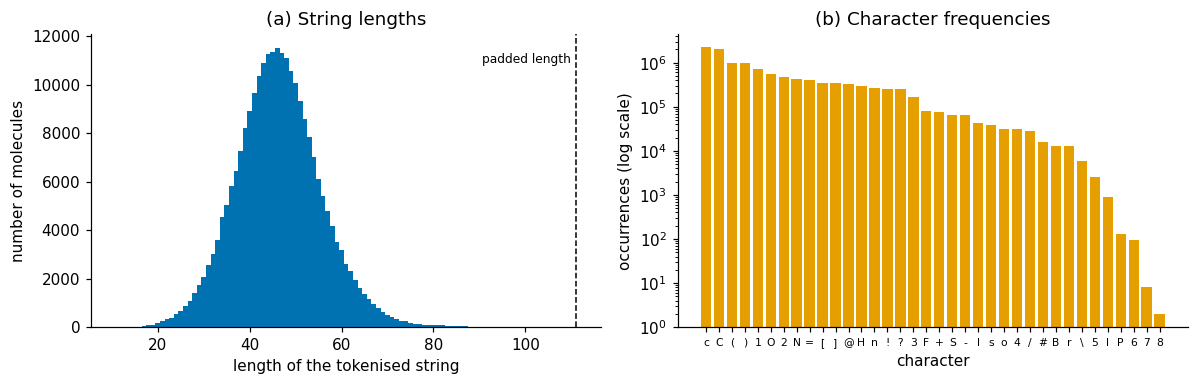

In [9]:
#@title Figure 2: what the data look like { display-mode: "form" }
lengths = np.array([len(s) for s in data])                       # tokens per molecule, including the two markers
counts = Counter(''.join(raw_smiles)); counts['!'] = counts['?'] = len(raw_smiles)

token_table = pd.DataFrame({"character": list(smiledict.keys()),
                            "occurrences": [counts[c] for c in smiledict]},
                           index=pd.Index(list(smiledict.values()), name="token"))
token_table.loc[pad_index] = ["<pad>", 0]                        # the padding token appears only after padding
print(f"{len(raw_smiles):,} molecules | length: min {lengths.min()}, median {int(np.median(lengths))}, max {lengths.max()} tokens")
display(token_table.T)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(lengths, bins=np.arange(lengths.min(), lengths.max() + 2) - 0.5, color=COLORS["blue"])
ax[0].axvline(maxlength, color="k", ls="--", lw=1); ax[0].text(maxlength - 1, ax[0].get_ylim()[1] * 0.9, "padded length", ha="right", fontsize=8)
ax[0].set(xlabel="length of the tokenised string", ylabel="number of molecules", title="(a) String lengths")
top = pd.Series({k: v for k, v in counts.items()}).sort_values(ascending=False)
ax[1].bar(range(len(top)), top.values, color=COLORS["orange"])
ax[1].set_xticks(range(len(top))); ax[1].set_xticklabels(top.index, fontsize=7); ax[1].set_yscale("log")
ax[1].set(xlabel="character", ylabel="occurrences (log scale)", title="(b) Character frequencies")
plt.tight_layout(); plt.show()

**Figure 2.** (a) Distribution of the string lengths; compare the typical (median) length printed above with the padded length of 111 tokens: a large part of each padded row is padding, which the model masks. (b) Character frequencies on a logarithmic scale: they span orders of magnitude, so the model sees far fewer examples of the rare characters than of the frequent ones.

### 3.4 The batches
After tokenising and padding we cut the training data into **batches** of 256 molecules (each batch is a tensor of shape 256 × 111) and keep the test data as one large batch. Let's look at the first training molecule: its tokens are followed by the padding index 36.

In [10]:
print(batch[0][0]) # All characters are tokenized followed by padding index 36

tensor([ 0,  1,  1,  2,  1,  3,  2,  1,  3,  4,  5,  4,  4,  4,  6,  7,  4,  4,
         2,  1,  1,  2,  8,  9,  3, 10,  4, 11,  4,  4,  4,  4,  4, 11, 12,  3,
         4,  6,  4,  5, 13, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36,
        36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36,
        36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36,
        36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36,
        36, 36, 36])


## 4. The model

### 4.1 Why a Transformer for SMILES?
A SMILES string is a sentence in a very strict language: a ring opened with `1` must be closed with another `1`, branches in parentheses must balance, and what is chemically allowed for one atom depends on its neighbours, often *far away in the string*. Recurrent networks struggle with such long-range dependencies. The **Transformer** (Vaswani et al., 2017) handles them with **attention**.

**Ingredients you will meet in the code** (see the original paper for details):

* **Embeddings.** Each token, and each *position* in the string, is mapped to a vector (`tok_embedding`, `pos_embedding`). Positions are needed because attention by itself does not know the order of the characters.
* **Self-attention.** Every position looks at all other positions and takes a weighted average of their representations; the weights (the *attention*) are learned. In **multi-head** attention (4 heads here) several such look-ups run in parallel.
* **Masks.** A *padding mask* hides the padding tokens. In the decoder a *causal mask* additionally hides all later positions, so that when predicting character $t$ the model can only use characters $1,\dots,t-1$.
* **Cross-attention.** Each decoder layer also attends to the output of the encoder, here the 10 latent vectors.
* **Residual connections and layer normalisation** around every sub-layer, plus a small **feed-forward network**, make deep stacks (6 layers here) trainable.

You do not need to write a Transformer yourself, because PyTorch has its own implementation. The code below builds every component explicitly so that you can see where each one lives, and comments the tensor shapes at each step.

### 4.2 From an autoencoder to a generator: the MMD penalty
An **autoencoder** compresses an input into a latent vector $z$ and rebuilds it. Trained alone, it can rebuild the training molecules perfectly, but the latent space it learns is irregular: a random $z$ usually decodes to garbage, so we cannot *generate*.

A **variational autoencoder** (VAE) fixes this by making the latent vectors of the whole data set look like draws from a simple **prior**, a standard normal distribution $N(0,I)$ (zero mean, unit variance in every direction). Then sampling $z \sim N(0,I)$ and decoding yields new molecules. The standard VAE enforces this with a KL-divergence term. Here we use a close relative, the **MMD autoencoder** (InfoVAE): the encoder outputs a single vector $z$ per molecule (no mean and variance), and a penalty on the **maximum mean discrepancy** (MMD) between the encoded vectors and samples from $N(0,I)$ pulls the *collection* of latent vectors toward the prior. For two samples $\{z_i\}$ and $\{y_j\}$ and a Gaussian kernel $k$,
$$\mathrm{MMD}^2=E\,k(z,z')+E\,k(y,y')-2\,E\,k(z,y),$$
where $E$ denotes the average over the samples.
(The implementation below is a simplified form, $8\,[1-\mathrm{mean}\,k(z,y)]$, which keeps only the cross term; implementing the full estimator is Exercise 1.)

**Noise.** During training we also add Gaussian noise (standard deviation 1) to $z$ before decoding, so the decoder learns to cope with perturbed latent vectors, as it will when it decodes random draws from the prior. This discourages **posterior collapse**, in which the decoder ignores the latent vector and simply behaves as a language model.

**Total loss** = cross-entropy (reconstruction, ignoring padding) + MMD penalty.

### 4.3 Architecture and code map

| Component | Setting |
|---|---|
| vocabulary | 37 tokens (36 characters + padding) |
| embedding size | 128 |
| encoder / decoder | 6 layers each, 4 attention heads, feed-forward width 256, dropout 0.1 |
| latent vector | encoder output $111\times128=14{,}208$ numbers → linear layer → **$10\times128=1280$ numbers** |
| decoder input | the latent vector → linear layer → two residual blocks → **10 "memory" vectors** of size 128 |
| trainable parameters | 21,859,969 (printed below) |

Where to look in the code: `Encoder`/`EncoderLayer` and `Decoder`/`DecoderLayer` (the Transformer parts), `Seq2Seq.forward` (the whole pipeline: encode → latent vector → add noise → decode), and `translate_sentence` (greedy generation, one character at a time).

In [11]:
class Encoder(nn.Module):
    def __init__(self,
                 input_dim,
                 hid_dim,
                 n_layers,
                 n_heads,
                 pf_dim,
                 dropout,
                 device,
                 max_length = 120):
        super().__init__()

        self.device = device

        self.tok_embedding = nn.Embedding(input_dim, hid_dim)
        self.pos_embedding = nn.Embedding(max_length, hid_dim)

        self.layers = nn.ModuleList([EncoderLayer(hid_dim,
                                                  n_heads,
                                                  pf_dim,
                                                  dropout,
                                                  device)
                                     for _ in range(n_layers)])

        self.dropout = nn.Dropout(dropout)

        self.scale = torch.sqrt(torch.FloatTensor([hid_dim])).to(device)

    def forward(self, src, src_mask):

        #src = [batch size, src len]
        #src_mask = [batch size, 1, 1, src len]

        batch_size = src.shape[0]
        src_len = src.shape[1]

        pos = torch.arange(0, src_len).unsqueeze(0).repeat(batch_size, 1).to(self.device)

        #pos = [batch size, src len]

        src = self.dropout((self.tok_embedding(src) * self.scale) + self.pos_embedding(pos))

        #src = [batch size, src len, hid dim]

        for layer in self.layers:
            src = layer(src, src_mask)

        #src = [batch size, src len, hid dim]

        return src

class EncoderLayer(nn.Module):
    def __init__(self,
                 hid_dim,
                 n_heads,
                 pf_dim,
                 dropout,
                 device):
        super().__init__()

        self.self_attn_layer_norm = nn.LayerNorm(hid_dim)
        self.ff_layer_norm = nn.LayerNorm(hid_dim)
        self.self_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.positionwise_feedforward = PositionwiseFeedforwardLayer(hid_dim,
                                                                     pf_dim,
                                                                     dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_mask):

        #src = [batch size, src len, hid dim]
        #src_mask = [batch size, 1, 1, src len]

        #self attention
        _src, _ = self.self_attention(src, src, src, src_mask)

        #dropout, residual connection and layer norm
        src = self.self_attn_layer_norm(src + self.dropout(_src))

        #src = [batch size, src len, hid dim]

        #positionwise feedforward
        _src = self.positionwise_feedforward(src)

        #dropout, residual and layer norm
        src = self.ff_layer_norm(src + self.dropout(_src))

        #src = [batch size, src len, hid dim]

        return src

class MultiHeadAttentionLayer(nn.Module):
    def __init__(self, hid_dim, n_heads, dropout, device):
        super().__init__()

        assert hid_dim % n_heads == 0

        self.hid_dim = hid_dim
        self.n_heads = n_heads
        self.head_dim = hid_dim // n_heads

        self.fc_q = nn.Linear(hid_dim, hid_dim)
        self.fc_k = nn.Linear(hid_dim, hid_dim)
        self.fc_v = nn.Linear(hid_dim, hid_dim)

        self.fc_o = nn.Linear(hid_dim, hid_dim)

        self.dropout = nn.Dropout(dropout)

        self.scale = torch.sqrt(torch.FloatTensor([self.head_dim])).to(device)

    def forward(self, query, key, value, mask = None):

        batch_size = query.shape[0]

        #query = [batch size, query len, hid dim]
        #key = [batch size, key len, hid dim]
        #value = [batch size, value len, hid dim]

        Q = self.fc_q(query)
        K = self.fc_k(key)
        V = self.fc_v(value)

        #Q = [batch size, query len, hid dim]
        #K = [batch size, key len, hid dim]
        #V = [batch size, value len, hid dim]

        Q = Q.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        K = K.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        V = V.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)

        #Q = [batch size, n heads, query len, head dim]
        #K = [batch size, n heads, key len, head dim]
        #V = [batch size, n heads, value len, head dim]

        energy = torch.matmul(Q, K.permute(0, 1, 3, 2)) / self.scale

        #energy = [batch size, n heads, query len, key len]

        if mask is not None:
            energy = energy.masked_fill(mask == 0, -1e10)

        attention = torch.softmax(energy, dim = -1)

        #attention = [batch size, n heads, query len, key len]

        x = torch.matmul(self.dropout(attention), V)

        #x = [batch size, n heads, query len, head dim]

        x = x.permute(0, 2, 1, 3).contiguous()

        #x = [batch size, query len, n heads, head dim]

        x = x.view(batch_size, -1, self.hid_dim)

        #x = [batch size, query len, hid dim]

        x = self.fc_o(x)

        #x = [batch size, query len, hid dim]

        return x, attention

class PositionwiseFeedforwardLayer(nn.Module):
    def __init__(self, hid_dim, pf_dim, dropout):
        super().__init__()

        self.fc_1 = nn.Linear(hid_dim, pf_dim)
        self.fc_2 = nn.Linear(pf_dim, hid_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        #x = [batch size, seq len, hid dim]

        x = self.dropout(torch.relu(self.fc_1(x)))

        #x = [batch size, seq len, pf dim]

        x = self.fc_2(x)

        #x = [batch size, seq len, hid dim]

        return x

class Decoder(nn.Module):
    def __init__(self,
                 output_dim,
                 hid_dim,
                 n_layers,
                 n_heads,
                 pf_dim,
                 dropout,
                 device,
                 max_length = 120):
        super().__init__()

        self.device = device
        self.hid_dim = hid_dim
        self.max_length = max_length
        self.tok_embedding = nn.Embedding(output_dim, hid_dim)
        self.pos_embedding = nn.Embedding(max_length, hid_dim)

        self.layers = nn.ModuleList([DecoderLayer(hid_dim,
                                                  n_heads,
                                                  pf_dim,
                                                  dropout,
                                                  device)
                                     for _ in range(n_layers)])

        self.fc_out = nn.Linear(hid_dim, output_dim)

        self.dropout = nn.Dropout(dropout)

        self.scale = torch.sqrt(torch.FloatTensor([hid_dim])).to(device)

    def forward(self, trg, enc_src, trg_mask, src_mask):

        #trg = [batch size, trg len]
        #enc_src = [batch size, src len, hid dim]
        #trg_mask = [batch size, 1, trg len, trg len]
        #src_mask = [batch size, 1, 1, src len]

        batch_size = trg.shape[0]
        trg_len = trg.shape[1]

        pos = torch.arange(0, trg_len).unsqueeze(0).repeat(batch_size, 1).to(self.device)

        #pos = [batch size, trg len]

        trg = self.dropout((self.tok_embedding(trg) * self.scale) + self.pos_embedding(pos))

        #trg = [batch size, trg len, hid dim]

        for layer in self.layers:
            trg, attention = layer(trg, enc_src, trg_mask, src_mask)

        #trg = [batch size, trg len, hid dim]
        #attention = [batch size, n heads, trg len, src len]

        output = self.fc_out(trg)

        #output = [batch size, trg len, output dim]

        return output, attention

class DecoderLayer(nn.Module):
    def __init__(self,
                 hid_dim,
                 n_heads,
                 pf_dim,
                 dropout,
                 device):
        super().__init__()

        self.self_attn_layer_norm = nn.LayerNorm(hid_dim)
        self.enc_attn_layer_norm = nn.LayerNorm(hid_dim)
        self.ff_layer_norm = nn.LayerNorm(hid_dim)
        self.self_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.encoder_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.positionwise_feedforward = PositionwiseFeedforwardLayer(hid_dim,
                                                                     pf_dim,
                                                                     dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, trg, enc_src, trg_mask, src_mask):

        #trg = [batch size, trg len, hid dim]
        #enc_src = [batch size, src len, hid dim]
        #trg_mask = [batch size, 1, trg len, trg len]
        #src_mask = [batch size, 1, 1, src len]

        #self attention
        _trg, _ = self.self_attention(trg, trg, trg, trg_mask)

        #dropout, residual connection and layer norm
        trg = self.self_attn_layer_norm(trg + self.dropout(_trg))

        #trg = [batch size, trg len, hid dim]

        #encoder attention
        _trg, attention = self.encoder_attention(trg, enc_src, enc_src, src_mask)

        #dropout, residual connection and layer norm
        trg = self.enc_attn_layer_norm(trg + self.dropout(_trg))

        #trg = [batch size, trg len, hid dim]

        #positionwise feedforward
        _trg = self.positionwise_feedforward(trg)

        #dropout, residual and layer norm
        trg = self.ff_layer_norm(trg + self.dropout(_trg))

        #trg = [batch size, trg len, hid dim]
        #attention = [batch size, n heads, trg len, src len]

        return trg, attention

class Seq2Seq(nn.Module):
    def __init__(self,
                 encoder,
                 decoder,
                 src_pad_idx,
                 trg_pad_idx,
                 device,
                 bottle_len
                 ):
        super().__init__()
        self.bottle_len = bottle_len
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.trg_pad_idx = trg_pad_idx
        self.device = device
        self.tanh = nn.Tanh()
        self.latent = nn.Linear(in_features = maxlength*self.decoder.hid_dim, out_features = bottle_len*self.decoder.hid_dim, bias = True)
        self.inverse = nn.Linear(in_features = bottle_len*self.decoder.hid_dim, out_features = bottle_len*self.decoder.hid_dim)
        self.resblock = nn.ModuleList([nn.Linear(in_features = bottle_len,out_features = bottle_len) for i in range(2)])
        self.relu = nn.ReLU()
    def make_src_mask(self, src):

        #src = [batch size, src len]

        src_mask = (src != self.src_pad_idx).unsqueeze(1).unsqueeze(2)

        #src_mask = [batch size, 1, 1, src len]

        return src_mask

    def make_trg_mask(self, trg):

        #trg = [batch size, trg len]

        trg_pad_mask = (trg != self.trg_pad_idx).unsqueeze(1).unsqueeze(2)

        #trg_pad_mask = [batch size, 1, 1, trg len]

        trg_len = trg.shape[1]

        trg_sub_mask = torch.tril(torch.ones((trg_len, trg_len), device = self.device)).bool()

        #trg_sub_mask = [trg len, trg len]

        trg_mask = trg_pad_mask & trg_sub_mask

        #trg_mask = [batch size, 1, trg len, trg len]

        return trg_mask

    def forward(self, src, trg):

        #src = [batch size, src len]
        #trg = [batch size, trg len]

        src_mask = self.make_src_mask(src)
        trg_mask = self.make_trg_mask(trg)

        enc_src = self.encoder(src, src_mask)

        latent = self.latent(enc_src.reshape(-1,maxlength*self.decoder.hid_dim)) # This is the generated latent vector
        noise_latent = latent + 1*torch.randn_like(latent) # We add noise in this part to prevent posterior collapse

        enc_src = self.inverse(noise_latent).reshape(-1,self.decoder.hid_dim,self.bottle_len)

        for l in self.resblock: # Further processing before passing through the decoder
          _enc_src = l(enc_src)
          enc_src = _enc_src + enc_src

        enc_src = enc_src.permute(0, 2, 1) # Permute the dimensions back




        output, attention = self.decoder(trg, enc_src, trg_mask, src_mask = None)

        #output = [batch size, trg len, output dim]
        #attention = [batch size, n heads, trg len, src len]

        return output, attention, latent # Here we have the attention but we do not use it


torch.manual_seed(8)

INPUT_DIM = len(invdict) # Number of unique characters in the dictionary
OUTPUT_DIM = len(invdict)
HID_DIM =  128 # The embedding dimension size
ENC_LAYERS = 6
DEC_LAYERS = 6
ENC_HEADS = 4 # HID_DIM must be integer divisible by head
DEC_HEADS = 4
ENC_PF_DIM = 2*HID_DIM # Encoder positional feedforward expansion dimension
DEC_PF_DIM = 2*HID_DIM # Decoder positional feedforward expansion dimension

ENC_DROPOUT = 0.1
DEC_DROPOUT = 0.1

bottle_len = 10 # The compression

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

enc = Encoder(INPUT_DIM,
              HID_DIM,
              ENC_LAYERS,
              ENC_HEADS,
              ENC_PF_DIM,
              ENC_DROPOUT,
              device,
              max_length = 120
              )

dec = Decoder(OUTPUT_DIM,
              HID_DIM,
              DEC_LAYERS,
              DEC_HEADS,
              DEC_PF_DIM,
              DEC_DROPOUT,
              device,
              max_length = 120
              )


model = Seq2Seq(enc, dec, pad_index, pad_index, device, bottle_len = bottle_len).to(device)


optimizer = optim.Adam(model.parameters(),lr = 0.0005) # Using Adam optimizer
criterion = nn.CrossEntropyLoss(ignore_index = pad_index,reduction = 'mean')# Ignore the value that corresponds to padding

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(model):,} trainable parameters')



def translate_sentence(src, model, device, max_len = 120, randz = False, return_Z = False):
    # randz controls if we are drawing a random vector
    model.eval()

    src_tensor = src.to(device).view(1,-1)

    src_mask = model.make_src_mask(src_tensor)
    with torch.no_grad():
        #src_mask = [batch size, 1, 1, src len]
        #trg_mask = [batch size, 1, trg len, trg len]
        enc_src = model.encoder(src_tensor, src_mask)
        #enc_src = [batch size, src len, hid dim]


        z = model.latent(enc_src.reshape(-1,maxlength*model.decoder.hid_dim))

        if(randz == True):
          z = torch.randn_like(z)

        enc_src = model.inverse(z).reshape(-1,model.decoder.hid_dim,model.bottle_len)

        for l in model.resblock:
          _enc_src = l(enc_src)
          enc_src = _enc_src + enc_src

        enc_src = enc_src.permute(0, 2, 1)

        #print('The context vector is:',z)


    trg_indexes = [0] # 0 is the token for start

    for i in range(max_len):

        trg_tensor = torch.LongTensor(trg_indexes).unsqueeze(0).to(device)
        #print(trg_tensor.shape)
        trg_mask = model.make_trg_mask(trg_tensor)

        with torch.no_grad():
            output, attention = model.decoder(trg_tensor, enc_src, trg_mask, src_mask = None)
        #print(output.argmax(2)[0])
        pred_token = output.argmax(2)[:,-1].item()

        trg_indexes.append(pred_token)

        if pred_token == smiledict['?']:
            break
    output = ''
    for i in trg_indexes:
      output += invdict[i]


    if(return_Z == True):
        return(z)
    return output[1:-1]#, attention

The model has 21,859,969 trainable parameters


## 5. Training and loading the model

Training combines the cross-entropy and MMD losses with the Adam optimiser. It is time-consuming (about 5 minutes per epoch on a T4, and many epochs are needed), and this method requires care: with a **small MMD weight** the model reconstructs molecules accurately but random latent vectors decode poorly; with a **large MMD weight** the latent space matches the prior and sampling works, but reconstructions get worse. In practice one starts with a small weight and **increases it gradually** while monitoring both the reconstruction accuracy and the validity of sampled molecules (Section 6). The training cell below uses a fixed weight, and gradually increasing it is part of Exercise 3.

We therefore **do not recommend training from scratch** here. For demonstration, a model that was already trained accompanies this tutorial. The training code is provided for those who want to explore (set `RUN_TRAINING` below); its loss curves are plotted at the end of the section.

**Teacher forcing.** During training the decoder receives the true string shifted by one position (`trg[:, :-1]`) and must predict the next character at every position (`trg[:, 1:]`). At generation time it feeds back its own predictions instead.

### 5.1 Loading the pre-trained model
A pickled model remembers the device it was saved on, so the next cell maps it to the device of your current runtime (GPU or CPU). Importantly, it also **creates a fresh optimiser for the loaded model**: the optimiser created in the previous section still points at the parameters of the discarded, untrained model. If you provided a `state_dict` file instead, the weights are loaded into the model built in Section 4 with `weights_only=True`.

In [12]:
#@title Load the pre-trained model { display-mode: "form" }
def relocate(m, device):
  """Move a (pickled) model to `device`.

  The classes above keep `device` and `scale` as plain attributes (not parameters/buffers), so
  `m.to(device)` alone does not update them; we do it by hand."""
  m.to(device)
  for sub in m.modules():
    if hasattr(sub, 'device'):
      sub.device = device
    if hasattr(sub, 'scale') and torch.is_tensor(sub.scale):
      sub.scale = sub.scale.to(device)
  return m

class _DeviceUnpickler(pickle.Unpickler):
  """Unpickle a whole model, mapping tensors saved on a GPU to the current device (works on CPU runtimes too)."""
  def find_class(self, module, name):
    if module == 'torch.storage' and name == '_load_from_bytes':
      return lambda b: torch.load(io.BytesIO(b), map_location=device, weights_only=False)
    return super().find_class(module, name)

if MODEL_PATH is None:
  print("No pre-trained model provided: keeping the randomly initialised model from the previous section.")
elif MODEL_PATH.endswith(".pt"):                       # weights only: the safe format
  model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
  model.eval()
  optimizer = optim.Adam(model.parameters(), lr = 0.0005)
  print(f'Loaded the state_dict {MODEL_PATH}: {count_parameters(model):,} trainable parameters, running on {device}')
else:                                                  # a pickled model (only load files that you trust!)
  with open(MODEL_PATH, 'rb') as f:
    model = _DeviceUnpickler(f).load()
  model = relocate(model, device)
  model.eval()
  # A new optimizer is needed: the old one still points at the parameters of the discarded model.
  optimizer = optim.Adam(model.parameters(), lr = 0.0005)
  print(f'Loaded {MODEL_PATH}: {count_parameters(model):,} trainable parameters, running on {device}')

Loaded VAE_transformer_model.pckl: 21,859,969 trainable parameters, running on cuda


In [13]:
#@title (Optional) Export the weights as a state_dict { display-mode: "form" }
#@markdown Saves only the numbers (not the code), which is the safe, portable way to share a model.
export_state_dict = False #@param {type:"boolean"}
if export_state_dict:
  fname = "VAE_transformer_state_dict.pt"
  torch.save(model.state_dict(), fname)
  digest = hashlib.sha256(open(fname, "rb").read()).hexdigest()
  print(f"saved {fname} ({os.path.getsize(fname)/1e6:.1f} MB)\nSHA-256: {digest}")
  print("model configuration: HID_DIM=%d, layers=%d/%d, heads=%d/%d, pf_dim=%d, bottle_len=%d, pad_index=%d" %
        (HID_DIM, ENC_LAYERS, DEC_LAYERS, ENC_HEADS, DEC_HEADS, ENC_PF_DIM, bottle_len, pad_index))
  if IN_COLAB:
    from google.colab import files
    files.download(fname)

In [14]:
#@title Run (optional) training? { display-mode: "form" }
RUN_TRAINING = False #@param {type:"boolean"}
N_EPOCHS = 1 #@param {type:"integer"}
#@markdown One epoch takes roughly 5 minutes on a T4 GPU. Leave off to evaluate the pre-trained model as it is.
if RUN_TRAINING and MODEL_PATH is None:
  print("NOTE: no pre-trained model was loaded, so a single epoch will not give a useful model "
        "(the original model needed many epochs and a gradually increased MMD weight).")

In [15]:
history = {'ce': [], 'mmd': []}   # losses recorded every 10 batches, for plotting

def K(x, y): # This computes the kernel function between x and y
    x_size = x.shape[0]
    y_size = y.shape[0]
    dim = x.shape[1]
    tiled_x = x.view(x_size,1,dim).repeat(1, y_size,1)
    tiled_y = y.view(1,y_size,dim).repeat(x_size, 1,1)

    return torch.exp(-torch.mean((tiled_x - tiled_y)**2,dim=2)/(dim*0.0005)) # [batch_size, 1]


def mmd(x, y): # The MMD loss between x and y

    return 2*2*2*(1 - torch.mean(K(x, y)))

def train(model, train_batch, optimizer, criterion, clip):

    model.train()

    for i in tqdm(range(len(train_batch))):

        data = train_batch[i]
        src = data.to(device)
        trg = data.to(device)
        #trg = [batch size, trg len]
        optimizer.zero_grad()

        outputs = model(src, trg[:,:-1]) # The second output is the attention
        output = outputs[0]
        #output = [batch size, trg len - 1, output dim]
        latent = outputs[-1]

        output_dim = output.shape[-1]

        output = output.reshape(-1, output_dim)
        trg = trg[:,1:].reshape(-1)
        # The MMD loss compares the latent distribution to a standard normal distribution
        mmd_loss = mmd(latent, torch.randn(1000, bottle_len*HID_DIM, device=device))

        ce_loss = criterion(output, trg)
        loss = ce_loss + mmd_loss # Loss is the sum of cross entropy loss + MMD loss.

        if(i%10 == 0):
          history['ce'].append(ce_loss.item()); history['mmd'].append(mmd_loss.item())
        if(i%100 == 0):
          print('Cross Entropy Loss:', history['ce'][-1])
          print('MMD LOSS:', history['mmd'][-1])

        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)

        optimizer.step()

if RUN_TRAINING:
  for epoch in range(N_EPOCHS): # Train this for N_EPOCHS epochs
    print('Epoch:', epoch+1)
    train(model, batch[:], optimizer, criterion, 1)
    with torch.no_grad():
      name = translate_sentence(batch[0][0], model, device, max_len = 120) # Reconstruct a SMILES name
      if(is_SMILE(name)): # If this is a valid SMILES
        print(name)
      name = translate_sentence(batch[0][0], model, device, max_len = 120, randz = True) # Randomly draw a SMILES name
      if(is_SMILE(name)):
        print(name)
else:
  print('Training skipped (RUN_TRAINING is off).')

Training skipped (RUN_TRAINING is off).


In [16]:
#@title Figure 3: training curves { display-mode: "form" }
if history['ce']:
  fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
  steps_rec = np.arange(len(history['ce'])) * 10
  ax[0].plot(steps_rec, history['ce'], color=COLORS["blue"]); ax[0].set(xlabel="training step", ylabel="cross-entropy", title="(a) Reconstruction loss")
  ax[1].plot(steps_rec, history['mmd'], color=COLORS["pink"]); ax[1].set(xlabel="training step", ylabel="MMD term", title="(b) MMD penalty")
  plt.tight_layout(); plt.show()
else:
  print("No training was run in this session (RUN_TRAINING is off), so there are no curves to show.")

No training was run in this session (RUN_TRAINING is off), so there are no curves to show.


## 6. Evaluation

We ask three questions: (1) can the model **reconstruct** molecules, (2) does the latent space **match its prior**, so that random vectors are meaningful inputs, and (3) what do we get when we **sample** random vectors: how many valid, unique and novel molecules, and do they resemble the training data?

### 6.1 Reconstructing one molecule
Let's start with the first molecule, **CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1**: encode it, then decode its latent vector.

In [17]:
model.eval()
first = batch[0][0]                                              # the first training molecule
original = ind2seq([t for t in first if int(t) != pad_index])    # includes the markers '!' and '?'
print('Original SMILES (with start ! and end ? markers):')
print(original)

with torch.no_grad():
  name = translate_sentence(first, model, device, max_len = 120) # Reconstruct the SMILES (markers are removed)
print('Reconstructed:')
print(name)
print('parses as SMILES:', is_SMILE(name), '| exact reconstruction:', name == original[1:-1])

print('\nThe molecule looks like (drag to rotate):')
show_mol(original[1:-1], title='first training molecule')

Original SMILES (with start ! and end ? markers):
!CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1?
Reconstructed:
CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1
parses as SMILES: True | exact reconstruction: True

The molecule looks like (drag to rotate):


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 6.2 Does the latent space match the prior?
The MMD penalty is meant to make the latent vectors of real molecules look like draws from $N(0,I)$ in $d=1280$ dimensions. How do we check? A tempting test is to project the latent vectors on their first principal component and look at the histogram. **Be careful: this test is misleading when there are few molecules.** With $n$ points in $d$ dimensions, the first principal component of *perfect* $N(0,I)$ data has a standard deviation of about $1+\sqrt{d/n}$, not 1. For $n=256$ and $d=1280$ that is about 3.2 (we checked by simulation), so a wide histogram does *not* mean the distribution is wrong.

The fair comparison is with a **null reference**: random draws from $N(0,I)$ of the *same size* analysed in the *same way*. Figure 4 does this with four views:

* (a) the first principal component of the encoded vectors versus the null;
* (b) the variance along the first 40 principal components, versus the null: a few directions rising far above the null would mean that the latent vectors are spread very unevenly, with some directions dominating;
* (c) the length $\|z\|$ of each latent vector: for $N(0,I)$ it is concentrated near $\sqrt d\approx35.8$;
* (d) the standard deviation of each of the 1280 latent coordinates: the prior has 1.

We also compute the MMD penalty of the encoded vectors against the prior, next to a reference value obtained from two independent prior samples.

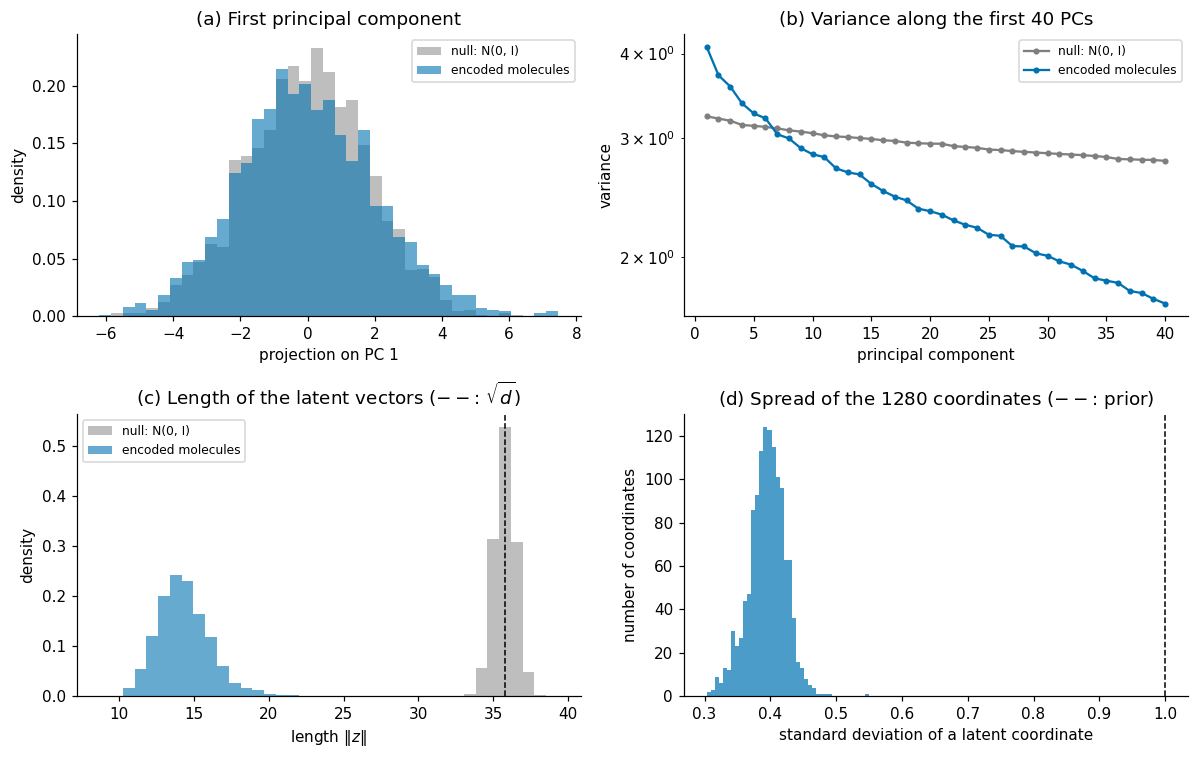

MMD term, encoded molecules vs prior : 6.672
MMD term, prior vs prior (reference) : 7.641
mean |z| = 14.3  (prior: 35.8);  mean coordinate std = 0.39  (prior: 1)


In [18]:
@torch.no_grad()
def encode_latents(src_batch, chunk=500):
    """Latent vectors (n x 1280, numpy) of a batch of tokenised molecules."""
    model.eval()
    out = []
    for start in range(0, len(src_batch), chunk):
        src = src_batch[start:start + chunk].to(device)
        enc = model.encoder(src, model.make_src_mask(src))
        out.append(model.latent(enc.reshape(-1, maxlength * model.decoder.hid_dim)).cpu())
    return torch.cat(out).numpy()

n_lat = 2000
Z = encode_latents(batch_test[0][:n_lat])                        # latent vectors of 2000 test molecules
d_lat = Z.shape[1]
P = np.random.default_rng(SEED).normal(size=Z.shape)             # null reference: same size, drawn from N(0, I)

def pc_analysis(A):
    Ac = A - A.mean(axis=0, keepdims=True)
    U_, s_, Vt_ = np.linalg.svd(Ac, full_matrices=False)
    return Ac @ Vt_[0], s_ ** 2 / (len(A) - 1)                  # projection on PC 1, variance of every PC

pc1_z, var_z = pc_analysis(Z)
pc1_p, var_p = pc_analysis(P)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
bins = np.linspace(min(pc1_z.min(), pc1_p.min()), max(pc1_z.max(), pc1_p.max()), 40)
ax[0, 0].hist(pc1_p, bins, density=True, alpha=0.5, color=COLORS["gray"], label="null: N(0, I)")
ax[0, 0].hist(pc1_z, bins, density=True, alpha=0.6, color=COLORS["blue"], label="encoded molecules")
ax[0, 0].set(xlabel="projection on PC 1", ylabel="density", title="(a) First principal component"); ax[0, 0].legend(fontsize=8)
ax[0, 1].semilogy(np.arange(1, 41), var_p[:40], "o-", ms=3, color=COLORS["gray"], label="null: N(0, I)")
ax[0, 1].semilogy(np.arange(1, 41), var_z[:40], "o-", ms=3, color=COLORS["blue"], label="encoded molecules")
ax[0, 1].set(xlabel="principal component", ylabel="variance", title="(b) Variance along the first 40 PCs"); ax[0, 1].legend(fontsize=8)
nb_ = np.linspace(min(np.linalg.norm(Z, axis=1).min(), np.linalg.norm(P, axis=1).min()) - 1, max(np.linalg.norm(Z, axis=1).max(), np.linalg.norm(P, axis=1).max()) + 1, 40)
ax[1, 0].hist(np.linalg.norm(P, axis=1), nb_, density=True, alpha=0.5, color=COLORS["gray"], label="null: N(0, I)")
ax[1, 0].hist(np.linalg.norm(Z, axis=1), nb_, density=True, alpha=0.6, color=COLORS["blue"], label="encoded molecules")
ax[1, 0].axvline(np.sqrt(d_lat), color="k", ls="--", lw=1); ax[1, 0].set(xlabel=r"length $\|z\|$", ylabel="density", title=r"(c) Length of the latent vectors ($--$: $\sqrt{d}$)"); ax[1, 0].legend(fontsize=8)
ax[1, 1].hist(Z.std(axis=0), bins=40, color=COLORS["blue"], alpha=0.7)
ax[1, 1].axvline(1.0, color="k", ls="--", lw=1); ax[1, 1].set(xlabel="standard deviation of a latent coordinate", ylabel="number of coordinates", title="(d) Spread of the 1280 coordinates ($--$: prior)")
plt.tight_layout(); plt.show()

with torch.no_grad():
    a = torch.tensor(Z[:256], dtype=torch.float32, device=device)
    p1, p2 = torch.randn(256, d_lat, device=device), torch.randn(256, d_lat, device=device)
    print(f"MMD term, encoded molecules vs prior : {mmd(a, p1).item():.3f}")
    print(f"MMD term, prior vs prior (reference) : {mmd(p1, p2).item():.3f}")
print(f"mean |z| = {np.linalg.norm(Z, axis=1).mean():.1f}  (prior: {np.sqrt(d_lat):.1f});  mean coordinate std = {Z.std(axis=0).mean():.2f}  (prior: 1)")

**Figure 4.** Compare the encoded vectors (blue) with the null reference (grey). The closer the two are, in all four panels and in the MMD numbers printed below, the better the latent space matches its prior, and the more likely it is that random draws decode to molecules. Remember that even a match does *not* guarantee that the decoder produces valid molecules from every point of the latent space (Section 6.3 measures that directly).

**Does the latent space organise molecules by their properties?** The data file contains logP and QED for every molecule. If the encoder has learned chemically meaningful structure, molecules that are close in latent space should have similar properties, which shows up as smooth colour gradients in a two-dimensional projection.

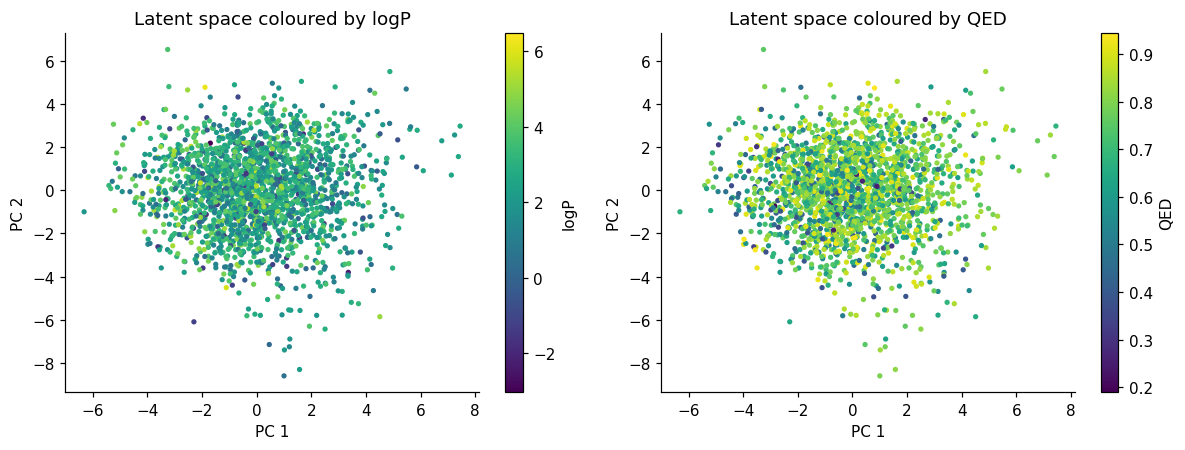

In [19]:
Z2 = PCA(n_components=2).fit_transform(Z)                          # 2-D projection of the 2000 latent vectors
props_test = csv.iloc[-testsize:].reset_index(drop=True).iloc[:n_lat]   # properties of the same test molecules

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, col, label in zip(ax, ("logP", "qed"), ("logP", "QED")):
    sc = a.scatter(Z2[:, 0], Z2[:, 1], c=props_test[col], s=6, cmap="viridis")
    fig.colorbar(sc, ax=a, label=label)
    a.set(xlabel="PC 1", ylabel="PC 2", title=f"Latent space coloured by {label}")
plt.tight_layout(); plt.show()

**Figure 5.** The same 2000 latent vectors coloured by logP (left) and QED (right). Smooth gradients would indicate that the latent space is organised by these properties. A random mix of colours would mean that the dominant directions of the latent space are unrelated to them. (A two-dimensional PCA captures only a small part of a 1280-dimensional space, so weak structure may be invisible here.)

### 6.3 Sampling new molecules
Now the real test. We draw random latent vectors from $N(0,I)$, decode them, and measure what we get. We follow the standard practice in the field (see the MOSES and GuacaMol benchmarks in the References):

| Metric | Definition |
|---|---|
| **Parses as SMILES** | RDKit can read the string (grammar only). This was the "validity" of the original tutorial. |
| **Chemically valid** | the string also passes RDKit's sanitisation (valence rules, aromaticity). **This is the validity that matters.** |
| **Repeated** | valid generated molecules that duplicate another generated molecule (complement of *uniqueness*). |
| **Novel** | distinct valid molecules that are not in the 250,000 ZINC molecules. Both sides are converted to RDKit's **canonical SMILES** first, so that the same molecule written in a different atom order is still recognised. |
| **Exactly reconstructed** | test molecules that are decoded back to the identical string. |

The helper functions below generate molecules in chunks (to limit GPU memory).

In [20]:
def tokens_to_smiles(tokens):
    # Convert a sequence of tokens into a SMILES string: stop at the end marker '?', drop the start marker '!'
    chars = []
    for t in tokens:
        c = invdict[int(t)]
        if c == '?':
            break
        chars.append(c)
    return ''.join(chars)[1:]

def latent_to_memory(z):
    # Turn latent vectors z [n, bottle_len*hid_dim] into the 'memory' that the decoder attends to
    enc_src = model.inverse(z).reshape(-1, model.decoder.hid_dim, model.bottle_len)
    for l in model.resblock:
        _enc_src = l(enc_src)
        enc_src = _enc_src + enc_src
    return enc_src.permute(0, 2, 1)

@torch.no_grad()
def decode_memory(enc_src, max_len = 120):
    # Greedy autoregressive decoding of a whole batch of memories into SMILES strings
    n = enc_src.shape[0]
    trg_indexes = torch.full((n, 1), smiledict['!'], dtype = torch.long, device = enc_src.device) # start token
    for i in range(max_len):
        trg_mask = model.make_trg_mask(trg_indexes)
        output, attention = model.decoder(trg_indexes, enc_src, trg_mask, src_mask = None)
        pred_token = output.argmax(2)[:,-1].view(-1,1)
        trg_indexes = torch.cat((trg_indexes, pred_token), dim = 1)
    return [tokens_to_smiles(row) for row in trg_indexes]

def group_generate(number = 100, device = device, max_len = 120, chunk = 500):
    # This function generates 'number' of molecules randomly (in chunks, to limit GPU memory use)
    model.eval()
    generated = []
    with torch.no_grad():
        for start in range(0, number, chunk):
            n = min(chunk, number - start)
            z = torch.randn(n, bottle_len*model.decoder.hid_dim, device = device) # random latent vectors
            generated += decode_memory(latent_to_memory(z), max_len)
    return generated

def group_translate(src, device = device, max_len = 120, chunk = 500):
    # This function reconstructs a group of molecules using batches
    model.eval()
    reconstructed = []
    with torch.no_grad():
        for start in range(0, len(src), chunk):
            src_tensor = src[start:start+chunk].to(device)
            src_mask = model.make_src_mask(src_tensor)
            enc_src = model.encoder(src_tensor, src_mask)
            z = model.latent(enc_src.reshape(-1, maxlength*model.decoder.hid_dim))
            reconstructed += decode_memory(latent_to_memory(z), max_len)
    return reconstructed

def generateZ(z, device = device, max_len = 120):
    # This function generates a molecule from a single latent representation z
    model.eval()
    z = z.to(device).view(1, -1)
    with torch.no_grad():
        return decode_memory(latent_to_memory(z), max_len)[0]

**Reference set and sampling.** First we canonicalise the ZINC molecules (about a minute and a half), then we draw 5000 random latent vectors and decode them. The random seed is fixed, so the numbers are reproducible on the same hardware.

In [21]:
def canonical(smiles):
  # RDKit's canonical SMILES (same molecule -> same string); None if the string is not a valid molecule
  m = Chem.MolFromSmiles(smiles)
  return Chem.MolToSmiles(m) if m is not None else None

# Canonical forms of all ZINC molecules (takes about a minute)
zinc_canonical = set(filter(None, (canonical(s) for s in tqdm(raw_smiles, desc = 'canonicalising ZINC'))))

set_seed(SEED)                                   # reproducible random latent vectors
numbers = 5000
generated_smiles = group_generate(numbers)

parse_ok = [s for s in generated_smiles if is_SMILE(s)]
valid = [s for s in generated_smiles if is_valid_molecule(s)]
valid_canonical = [canonical(s) for s in valid]
distinct = sorted(set(valid_canonical))
valid_unique_smiles = [s for s in distinct if s not in zinc_canonical] # new, valid, distinct molecules

# --- reconstruction of test molecules ---------------------------------------------------------
test_samples = 5000
testsmile = [tokens_to_smiles(batch_test[0][i]) for i in range(test_samples)]
reconstructed = group_translate(batch_test[0][:test_samples])
match = sum(testsmile[i] == reconstructed[i] for i in range(test_samples))
print(f'{numbers} molecules generated, {test_samples} test molecules reconstructed.')

canonicalising ZINC:   0%|          | 0/249455 [00:00<?, ?it/s]

5000 molecules generated, 5000 test molecules reconstructed.


In [22]:
def percent_with_ci(k, n):
    if n == 0:
        return float('nan'), float('nan')
    p = k / n
    return 100 * p, 100 * 1.96 * np.sqrt(p * (1 - p) / n)        # normal-approximation 95 % interval

rows = [("Parses as SMILES (grammar only)",        len(parse_ok),                         numbers),
        ("Chemically valid",                       len(valid),                            numbers),
        ("Repeated (among valid)",                 len(valid) - len(distinct),            len(valid)),
        ("Novel (among distinct valid)",           len(valid_unique_smiles),              len(distinct)),
        ("Exactly reconstructed (test molecules)", match,                                 test_samples)]
table = pd.DataFrame([(m, k, n, *percent_with_ci(k, n)) for m, k, n in rows],
                     columns=["Metric", "count", "out of", "percent", "95% CI (+/- points)"])
try:
    display(table.round(2).style.hide(axis="index"))
except Exception:
    display(table.round(2))

Metric,count,out of,percent,95% CI (+/- points)
Parses as SMILES (grammar only),4347,5000,86.940000,0.930000
Chemically valid,3971,5000,79.420000,1.120000
Repeated (among valid),161,3971,4.050000,0.610000
Novel (among distinct valid),3803,3810,99.820000,0.140000
Exactly reconstructed (test molecules),3429,5000,68.580000,1.290000


**Table 1.** Results for 5000 random samples and 5000 test molecules. The last column is the approximate 95 % margin of error from the finite number of samples (the denominators differ between rows). These are **single draws with a fixed seed**: another seed would give numbers within these margins, and a model trained with a different MMD weight would give different ones.

How to read the table:
* The gap between "parses" and "chemically valid" counts strings that look like SMILES but break chemistry rules (next cell shows how).
* "Novel" is measured against 250,000 molecules, a tiny part of chemical space. A high value shows that the model does not simply copy its training set; it does not mean that the molecules are new to chemistry, nor interesting.
* Reconstruction accuracy and sampling quality pull in opposite directions (Section 5): a stricter match to the prior usually lowers one and raises the other.

### How do the generated strings fail?
Not all invalid strings are alike. RDKit tells us whether a string cannot be parsed at all, or parses but violates valence or aromaticity rules.

In [23]:
def failure_kind(s):
    if len(s) == 0:
        return "empty string"
    m = Chem.MolFromSmiles(s, sanitize=False)
    if m is None:
        return "syntax error (cannot be parsed)"
    try:
        Chem.SanitizeMol(m)
        return "valid"
    except Exception as e:
        return type(e).__name__                                   # e.g. AtomValenceException, KekulizeException

kinds = Counter(failure_kind(s) for s in generated_smiles)
meaning = {"valid": "chemically valid molecule",
           "syntax error (cannot be parsed)": "unbalanced brackets or unclosed rings, not a legal SMILES",
           "AtomValenceException": "an atom has an impossible valence (too many bonds)",
           "AtomKekulizeException": "an aromatic ring cannot be written with alternating bonds",
           "KekulizeException": "an aromatic ring cannot be written with alternating bonds",
           "empty string": "the decoder produced no characters"}
print(f"{'outcome':36s} {'count':>6s} {'percent':>8s}   meaning")
for kind, k in kinds.most_common():
    print(f"{kind:36s} {k:6d} {100 * k / numbers:7.2f}%   {meaning.get(kind, 'other sanitisation error')}")
print("\nExamples of strings that fail:")
shown_kinds = Counter()
for s in generated_smiles:
    kind = failure_kind(s)
    if kind != "valid" and shown_kinds[kind] < 2:
        shown_kinds[kind] += 1; print(f"  [{kind}] {s[:90]}")

outcome                               count  percent   meaning
valid                                  3971   79.42%   chemically valid molecule
syntax error (cannot be parsed)         653   13.06%   unbalanced brackets or unclosed rings, not a legal SMILES
KekulizeException                       360    7.20%   an aromatic ring cannot be written with alternating bonds
AtomValenceException                     14    0.28%   an atom has an impossible valence (too many bonds)
AtomKekulizeException                     2    0.04%   an aromatic ring cannot be written with alternating bonds

Examples of strings that fail:
  [syntax error (cannot be parsed)] CCOc1ccc(C(=O)N2CCC[C@H](C)N2C[C@H]2CO)cc1F
  [syntax error (cannot be parsed)] CN1CCC(=O)CNC(=O)NC(=O)Cc2ccc(Cl)cc2
  [KekulizeException] Cc1nc(C[C@H](C)NC(=O)NCc2ccc(F)cc2Cl)cc1C
  [KekulizeException] Cc1ccc(-c2cc(OC)cc(-c3ccc(Cl)cc3)nc2C)cc1
  [AtomKekulizeException] CCn1cc(Br)cc1/C(=N/c1ccc2ncc(C)c(Cl)c2C)c1
  [AtomKekulizeException] CC[

### Do the generated molecules resemble the training data?
Validity, uniqueness and novelty say nothing about whether the new molecules are *like* the training molecules, which was the goal. A standard check compares **property distributions**. We compute logP and QED with RDKit for the novel generated molecules and for a random sample of 5000 ZINC molecules, with the same code for both.

logP  ZINC: mean 2.47, std 1.42 | generated: mean 2.65, std 1.27
QED   ZINC: mean 0.73, std 0.14 | generated: mean 0.81, std 0.10


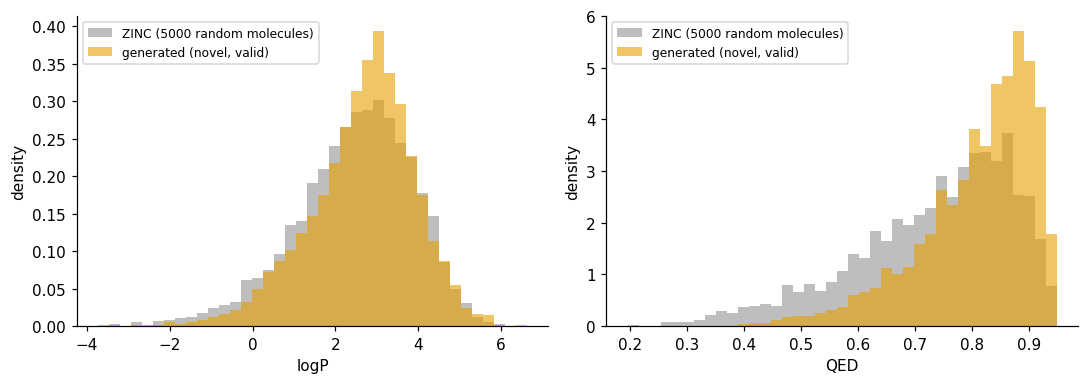

In [24]:
def properties(smiles_list):
    out = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        if m is None:
            continue
        try:
            out.append((Crippen.MolLogP(m), QED.qed(m)))
        except Exception:
            pass
    return np.array(out)

ref_idx = np.random.default_rng(SEED).choice(len(raw_smiles), size=5000, replace=False)
P_zinc = properties([raw_smiles[i] for i in ref_idx])
P_gen = properties(valid_unique_smiles)

if len(P_gen) == 0:
    print("No novel valid molecules were generated (is the pre-trained model loaded?), nothing to compare.")
else:
  fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
  for j, (name, a) in enumerate(zip(("logP", "QED"), ax)):
    lo, hi = min(P_zinc[:, j].min(), P_gen[:, j].min()), max(P_zinc[:, j].max(), P_gen[:, j].max())
    b = np.linspace(lo, hi, 40)
    a.hist(P_zinc[:, j], b, density=True, alpha=0.5, color=COLORS["gray"], label="ZINC (5000 random molecules)")
    a.hist(P_gen[:, j], b, density=True, alpha=0.6, color=COLORS["orange"], label="generated (novel, valid)")
    a.set(xlabel=name, ylabel="density"); a.legend(fontsize=8)
    print(f"{name:5s} ZINC: mean {P_zinc[:, j].mean():.2f}, std {P_zinc[:, j].std():.2f} | generated: mean {P_gen[:, j].mean():.2f}, std {P_gen[:, j].std():.2f}")
  plt.tight_layout(); plt.show()

**Figure 6.** Distributions of logP and QED for ZINC molecules (grey) and for the generated novel molecules (orange). Overlapping distributions mean that the generator reproduces the property profile of its training data; a shift reveals a bias of the model (for example toward smaller or simpler molecules).

### A random sample of generated molecules
The twelve molecules below are a **random sample** (fixed seed) of the novel, valid molecules, labelled with their QED and logP. (Showing the *first* twelve of an alphabetically sorted list would give a biased picture, since strings that start with the same characters would dominate.)

In [25]:
valid_unique_smiles = list(valid_unique_smiles)
if not valid_unique_smiles:
    print("No novel valid molecules were generated (is the pre-trained model loaded?).")
    ms, legends = [], []
else:
    pick = np.random.default_rng(SEED).choice(len(valid_unique_smiles), size=min(12, len(valid_unique_smiles)), replace=False)
    ms = [Chem.MolFromSmiles(valid_unique_smiles[i]) for i in pick]
    legends = [f"QED {QED.qed(m):.2f} | logP {Crippen.MolLogP(m):.1f}" for m in ms]
show_grid(ms, legends, ncols=4, cell=(300, 250)) if ms else None

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**Figure 7.** Twelve randomly chosen novel generated molecules (interactive 3D views: drag to rotate, scroll to zoom; the 3D structures are plausible conformers generated with RDKit, not computed minima). They parse and pass RDKit's valence checks and are not in the ZINC set we trained on, which is encouraging, but be careful with the conclusions: a chemically *valid* structure is not necessarily **stable, synthesisable or useful**, and "not in this 250k data set" does not mean "never seen before". Any real application needs further filtering (synthetic-accessibility and property scores, substructure alerts) and expert review.

## 7. Interpolating between two molecules

**What else can we use the model for?** Because the latent space is continuous, we can walk from the latent vector of one molecule to that of another and decode the points along the way: a path of **intermediate molecules**.

Here we use **ibuprofen** and **caffeine**. We encode the two molecules into latent vectors $z_I$ and $z_C$, define the direction $d=z_C-z_I$, and decode 7 equally spaced points $z_I+\tfrac{i}{6}d$, $i=0,\dots,6$, which include both end points. Two things to keep in mind: the straight line in latent space need not pass through valid molecules (some steps may be invalid), and the *decoded* end points need not be exactly the input molecules, since reconstruction is not perfect.

In [26]:
Caffeine = '!CN1C=NC2=C1C(=O)N(C(=O)N2C)C?'
Ibuprofen = '!CC(C)CC1=CC=C(C=C1)C(C)C(=O)O?'

Caffeine_token = char2ind(Caffeine,smiledict)
Ibuprofen_token = char2ind(Ibuprofen,smiledict)

pad(Caffeine_token,maxlength)
pad(Ibuprofen_token,maxlength)

Caffeine_token = torch.LongTensor(Caffeine_token).to(device)
Ibuprofen_token = torch.LongTensor(Ibuprofen_token).to(device)

In [27]:
Caffeine_rec = translate_sentence(Caffeine_token, model, device, max_len = 120)
Ibuprofen_rec = translate_sentence(Ibuprofen_token, model, device, max_len = 120)
print("Caffeine  in :", Caffeine[1:-1]);  print("Caffeine  out:", Caffeine_rec)
print("Ibuprofen in :", Ibuprofen[1:-1]); print("Ibuprofen out:", Ibuprofen_rec)

def mol_or_none(s):
    return Chem.MolFromSmiles(s) if is_valid_molecule(s) else None

exact = lambda a, b: canonical(a) is not None and canonical(a) == canonical(b)
show_grid(
    [mol_or_none(Ibuprofen[1:-1]), mol_or_none(Ibuprofen_rec), mol_or_none(Caffeine[1:-1]), mol_or_none(Caffeine_rec)],
    ncols=4, cell=(260, 240),
    legends=["Ibuprofen (input)", "Ibuprofen decoded" + ("" if exact(Ibuprofen_rec, Ibuprofen[1:-1]) else " (different!)"),
             "Caffeine (input)", "Caffeine decoded" + ("" if exact(Caffeine_rec, Caffeine[1:-1]) else " (different!)")])

Caffeine  in : CN1C=NC2=C1C(=O)N(C(=O)N2C)C
Caffeine  out: CN1C=NC2=C1C(=O)N(C(=O)N2C)C
Ibuprofen in : CC(C)CC1=CC=C(C=C1)C(C)C(=O)O
Ibuprofen out: CC(C)CC1=CC=CC(=C1)C(C)C(=O)O


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**Figure 8.** Inputs and their reconstructions. Caffeine is reconstructed exactly. With the pre-trained model provided with this tutorial, the decoded ibuprofen is **not** ibuprofen: it has the isobutyl and propionic-acid substituents on the *meta* rather than the *para* positions of the benzene ring, so it is a structural isomer. This is a good reminder of what an imperfect reconstruction means chemically: a SMILES string that differs in a single position describes a different molecule, with possibly different properties. (Reconstruction was 68.6 % exact on the test set with this model, so about a third of molecules come back changed.) For the demonstration we keep going with the latent vectors of the *true* ibuprofen and caffeine.

In [28]:
Z_Caffeine = translate_sentence(Caffeine_token,model,device,max_len = 120,return_Z=True) # Generating the Z vector for Caffeine
Z_Ibuprofen  = translate_sentence(Ibuprofen_token,model,device,max_len = 120,return_Z=True)# Generating the Z vector for Ibuprofen
Z_direction = Z_Caffeine - Z_Ibuprofen

steps = 7
mols = []

for i in range(steps):
  step_size = i/(steps - 1)
  mols.append(generateZ(Z_Ibuprofen+ step_size*Z_direction))

In [29]:
_fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def tanimoto(m1, m2):
    return DataStructs.TanimotoSimilarity(_fpgen.GetFingerprint(m1), _fpgen.GetFingerprint(m2))

ref_ibu, ref_caf = Chem.MolFromSmiles(Ibuprofen[1:-1]), Chem.MolFromSmiles(Caffeine[1:-1])
step_mols, step_legends, sim_ibu, sim_caf = [], [], [], []
for k, s in enumerate(mols):
    m = Chem.MolFromSmiles(s) if is_valid_molecule(s) else None
    step_mols.append(m)
    if m is None:                                                  # make invalid steps explicit
        step_legends.append(f"step {k}: invalid SMILES"); sim_ibu.append(np.nan); sim_caf.append(np.nan)
    else:
        si, sc_ = tanimoto(m, ref_ibu), tanimoto(m, ref_caf)
        step_legends.append(f"step {k}: sim(ibu) {si:.2f} | sim(caf) {sc_:.2f}"); sim_ibu.append(si); sim_caf.append(sc_)

show_grid(step_mols, step_legends, ncols=4, cell=(300, 250))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

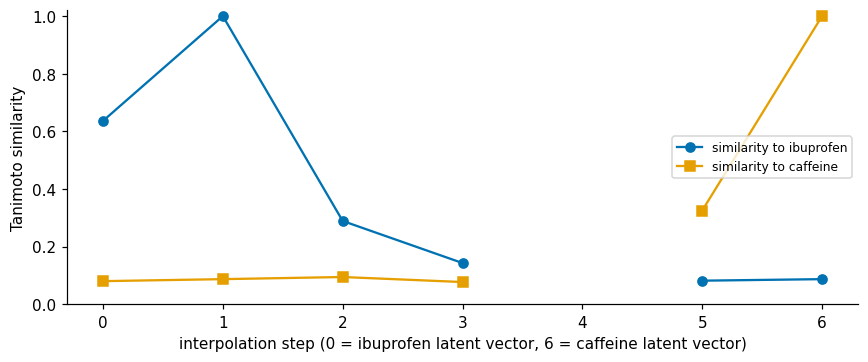

In [30]:
fig, axl = plt.subplots(figsize=(8, 3.4))
axl.plot(range(steps), sim_ibu, "o-", color=COLORS["blue"], label="similarity to ibuprofen")
axl.plot(range(steps), sim_caf, "s-", color=COLORS["orange"], label="similarity to caffeine")
axl.set(xlabel="interpolation step (0 = ibuprofen latent vector, 6 = caffeine latent vector)", ylabel="Tanimoto similarity", ylim=(0, 1.02))
axl.set_xticks(range(steps)); axl.legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()

**Figure 9.** Decoded molecules along the straight line from ibuprofen (step 0) to caffeine (step 6) as interactive 3D views, with the Tanimoto similarity (Morgan fingerprints) of each molecule to the two end points; steps that decode to an invalid string are marked. The plot below shows the same similarities as curves. With the pre-trained model provided here, the path starts at the *meta* isomer of ibuprofen, immediately passes through true ibuprofen (step 1), then through two molecules that are neither (steps 2 and 3), one invalid string (step 4), and a close analogue of caffeine (step 5) before reaching caffeine (step 6). The similarity curves show how the molecules change *gradually* from one end point to the other, even though a few of the intermediate structures are chemically odd. Different models, or a path in a different direction, will give different intermediates.

## 8. Check your understanding

1. Why do we add an end character `?` to every string, and what would go wrong without it?
2. How many numbers describe one molecule in the latent space of this model?
3. What does the MMD term do, and what would happen to random samples without it?
4. A model reconstructs 99 % of test molecules exactly, but only 5 % of random samples are valid. What is probably wrong, and what would you change?
5. Why is a "novel" fraction of 99 % less impressive than it sounds?

<details><summary>Answers</summary>

1. The decoder generates one character at a time; the end marker tells it (and us) where the molecule stops. Without it the decoder would never know when to stop, and generated strings would need an arbitrary cut-off.
2. $10\times128=1280$ numbers.
3. It pulls the distribution of the latent vectors of real molecules toward $N(0,I)$. Without it, the encoder can place molecules anywhere, and random draws from $N(0,I)$ usually fall in regions that the decoder never saw: they decode to invalid strings.
4. The latent space does not match its prior, so random vectors are out of distribution: the MMD weight is too small (a plain autoencoder). Increase the MMD weight, and check Figure 4.
5. ZINC has only 250,000 molecules, a minute part of chemical space, so almost any reasonable molecule is "not in ZINC". Novelty alone says nothing about quality; compare the property distributions (Figure 6) and check stability and synthesisability.
</details>

### Exercises
1. **The full MMD.** Replace the simplified `mmd` by the full estimator $E\,k(z,z')+E\,k(y,y')-2\,E\,k(z,y)$ and compare the diagnostics of Figure 4 after a short training run.
2. **The noise level.** Change the noise standard deviation added to $z$ in `Seq2Seq.forward` (currently 1) and study reconstruction accuracy against sampling validity.
3. **MMD schedule.** Train with an MMD weight that grows during training and plot reconstruction accuracy and validity as functions of the weight.
4. **Sampling instead of argmax.** Replace the greedy choice `output.argmax(2)` by sampling from the predicted distribution with a temperature. How do validity, repeats and novelty change?
5. **More interpolations.** Interpolate between other pairs of molecules and plot the similarity curves. When is the path smooth, and when does it jump?
6. **A better filter.** Add a synthetic-accessibility score (the RDKit Contrib `sascorer`) and count how many generated molecules pass QED > 0.5 and SAS < 4.

## 9. Troubleshooting

| Symptom | What to do |
|---|---|
| `FileNotFoundError` / the file picker did not appear | Re-run the "Provide the data files" cell; for Drive, check `drive_folder`. |
| Warning that the csv differs from what the pre-trained model expects | The pre-trained model only works with the original `250k_rndm_zinc_drugs_clean_3.csv` (36 characters, maximum length 111). |
| `AttributeError: Can't get attribute 'Seq2Seq' ...` while loading a `.pckl` | Run the model-definition cell (Section 4) **before** the loading cell: the pickle refers to those class names. |
| `RuntimeError` or key mismatch when loading a `.pt` file | The `state_dict` must come from this architecture (same sizes); run the model-definition cell first. |
| `CUDA out of memory` | Lower `chunk` in `group_generate` / `group_translate`, or restart the runtime. |
| Everything is extremely slow | You are on a CPU runtime: **Runtime → Change runtime type → GPU**, then run again from the top. |
| Training loss does not go down after loading the model | Make sure the loading cell ran *after* the model-definition cell; it creates the optimiser for the loaded model. |

## References
* A. Vaswani et al., *Attention is all you need*, Advances in Neural Information Processing Systems 30 (2017). arXiv:1706.03762
* D. P. Kingma, M. Welling, *Auto-encoding variational Bayes*, ICLR (2014). arXiv:1312.6114
* S. Zhao, J. Song, S. Ermon, *InfoVAE: Information maximizing variational autoencoders* (2017). arXiv:1706.02262
* A. Gretton et al., *A kernel two-sample test*, J. Mach. Learn. Res. **13**, 723–773 (2012).
* S. R. Bowman et al., *Generating sentences from a continuous space*, CoNLL (2016). (Posterior collapse.)
* R. Gómez-Bombarelli et al., *Automatic chemical design using a data-driven continuous representation of molecules*, ACS Cent. Sci. **4**, 268–276 (2018).
* W. Jin, R. Barzilay, T. Jaakkola, *Junction tree variational autoencoder for molecular graph generation*, ICML (2018). arXiv:1802.04364
* D. Weininger, *SMILES, a chemical language and information system*, J. Chem. Inf. Comput. Sci. **28**, 31–36 (1988).
* T. Sterling, J. J. Irwin, *ZINC 15 – ligand discovery for everyone*, J. Chem. Inf. Model. **55**, 2324–2337 (2015).
* D. Polykovskiy et al., *Molecular Sets (MOSES): a benchmarking platform for molecular generation models*, Front. Pharmacol. **11**, 565644 (2020).
* N. Brown et al., *GuacaMol: benchmarking models for de novo molecular design*, J. Chem. Inf. Model. **59**, 1096–1108 (2019).
* G. Landrum, *RDKit: open-source cheminformatics*, https://www.rdkit.org
* N. Rego, D. Koes, *3Dmol.js: molecular visualization with WebGL*, Bioinformatics **31**, 1322–1324 (2015). (The viewer behind py3Dmol.)